In [3]:
%pip install numpy pandas matplotlib seaborn scikit-learn xgboost shap

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# ============================================================
# 1. MEMBACA DATASET UMKM
# ============================================================

df = pd.read_csv('synthetic_umkm_data.csv')

print("5 Baris Pertama Dataset:")
display(df.head())

print("\nInformasi Dataset:")
df.info()

# ============================================================
# 2. PREPROCESSING DATA
# ============================================================

target_col = df.columns[-1]

print(f"\nTarget variabel: {target_col}")

X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()


if 'ID' in X.columns:
    X = X.drop(columns=['ID'])
    print("Kolom ID dihapus.")
    
# A. Hapus teks ulasan bebas untuk model awal
if 'Review_Text' in X.columns:
    X = X.drop(columns=['Review_Text'])
    print("Kolom Review_Text dihapus karena berisi teks bebas.")

# B. Encode kategori Peak_Hour_Latency berdasarkan urutannya
if 'Peak_Hour_Latency' in X.columns:
    latency_mapping = {
        'Low': 0,
        'Med': 1,
        'High': 2
    }

    X['Peak_Hour_Latency'] = (
        X['Peak_Hour_Latency']
        .astype(str)
        .str.strip()
        .map(latency_mapping)
    )

# Pastikan tidak ada kategori yang gagal dipetakan
if 'Peak_Hour_Latency' in X.columns:
    if X['Peak_Hour_Latency'].isna().any():
        raise ValueError(
            "Ada nilai Peak_Hour_Latency yang tidak dikenali."
        )

# C. Encode kolom kategorikal lain jika ada
for col in X.select_dtypes(
    include=['object', 'category', 'string']
).columns:

    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))

# D. Encode target Class
le_y = LabelEncoder()
y = le_y.fit_transform(y.astype(str))

print("\nMapping kelas target:")
for angka, kelas in enumerate(le_y.classes_):
    print(f"{kelas} -> {angka}")

print("\nTipe data fitur:")
print(X.dtypes)

# Pastikan tidak ada fitur bertipe string
invalid_cols = X.select_dtypes(
    exclude=['number', 'bool']
).columns.tolist()

if invalid_cols:
    raise ValueError(
        f"Kolom yang belum numerik: {invalid_cols}"
    )

# ============================================================
# 3. MEMBAGI DATA TRAINING DAN TESTING
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

# ============================================================
# 4. MEMBUAT MODEL XGBOOST CLASSIFIER
# ============================================================

model = xgb.XGBClassifier(
    objective='multi:softprob',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='mlogloss'
)

# ============================================================
# 5. MELATIH MODEL
# ============================================================

print("\nMemulai proses training XGBoost...")

model.fit(X_train, y_train)

print("Training selesai!")

# ============================================================
# 6. EVALUASI PERFORMA MODEL
# ============================================================

y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)

print(f"\nAkurasi Model: {akurasi * 100:.2f}%")

print("\nLaporan Klasifikasi:")

report_dict = classification_report(
    y_test,
    y_pred,
    labels=list(range(len(le_y.classes_))),
    target_names=[str(kelas) for kelas in le_y.classes_],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

# Tampilkan semua metrik
display(report_df.round(4))

# Tampilkan contoh prediksi menggunakan label asli
hasil_prediksi = pd.DataFrame({
    'Aktual': le_y.inverse_transform(y_test),
    'Prediksi': le_y.inverse_transform(y_pred.astype(int))
})

print("\n10 Contoh Hasil Prediksi:")
display(hasil_prediksi.head(10))


5 Baris Pertama Dataset:


,ID,Monthly_Revenue,Net_Profit_Margin (%),Burn_Rate_Ratio,Transaction_Count,Avg_Historical_Rating,Review_Text,Review_Volatility,Business_Tenure_Months,Repeat_Order_Rate (%),Digital_Adoption_Score,Peak_Hour_Latency,Location_Competitiveness,Sentiment_Score,Class
0,1,6680716,22.72,0.811,161,4.75,"Transaksi digital lancar, proses checkout tida...",0.313,105,19.40,4.24,Low,9,-0.25,Growth
1,2,5819101,4.46,0.968,104,4.21,"Harga dan kualitas seimbang, pengalaman biasa ...",0.632,95,14.87,1.27,Med,10,0.00,Growth
2,3,5236404,-10.12,1.047,102,3.51,"Pelayanan standar, masih bisa ditingkatkan.",0.470,17,21.00,3.37,Med,8,0.00,Struggling
3,4,8043552,0.04,0.969,99,4.33,"Transaksi digital lancar, proses checkout tida...",0.206,109,30.62,5.41,Low,13,-0.25,Growth
4,5,6071256,4.22,0.954,115,4.34,Selalu repeat order karena kualitasnya terjaga...,0.232,74,20.87,2.67,Low,7,0.25,Growth



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        150000 non-null  int64  
 1   Monthly_Revenue           150000 non-null  int64  
 2   Net_Profit_Margin (%)     150000 non-null  float64
 3   Burn_Rate_Ratio           150000 non-null  float64
 4   Transaction_Count         150000 non-null  int64  
 5   Avg_Historical_Rating     150000 non-null  float64
 6   Review_Text               150000 non-null  str    
 7   Review_Volatility         150000 non-null  float64
 8   Business_Tenure_Months    150000 non-null  int64  
 9   Repeat_Order_Rate (%)     150000 non-null  float64
 10  Digital_Adoption_Score    150000 non-null  float64
 11  Peak_Hour_Latency         150000 non-null  str    
 12  Location_Competitiveness  150000 non-null  int64  
 13  Sentiment_Score           150000 no

,precision,recall,f1-score,support
Critical,0.9960,0.9801,0.9880,2512.0000
Elite,0.9956,0.9902,0.9929,2038.0000
Growth,0.9982,0.9985,0.9984,17136.0000
Struggling,0.9921,0.9976,0.9948,8314.0000
accuracy,0.9962,0.9962,0.9962,0.9962
macro avg,0.9955,0.9916,0.9935,30000.0000
weighted avg,0.9962,0.9962,0.9962,30000.0000



10 Contoh Hasil Prediksi:


,Aktual,Prediksi
0,Growth,Growth
1,Growth,Growth
2,Growth,Growth
3,Growth,Growth
4,Growth,Growth
5,Critical,Critical
6,Struggling,Struggling
7,Growth,Growth
8,Critical,Critical
9,Struggling,Struggling


--- TABEL RANKING FITUR PALING BERPENGARUH ---
                 Feature  Importance
   Net_Profit_Margin (%)    0.428839
         Burn_Rate_Ratio    0.242736
   Repeat_Order_Rate (%)    0.141249
       Peak_Hour_Latency    0.090800
   Avg_Historical_Rating    0.053473
Location_Competitiveness    0.026839
  Business_Tenure_Months    0.012709
       Review_Volatility    0.000770
         Sentiment_Score    0.000704
  Digital_Adoption_Score    0.000691
         Monthly_Revenue    0.000636
       Transaction_Count    0.000554


C:\Users\Alvis\AppData\Local\Temp\ipykernel_24088\907158248.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


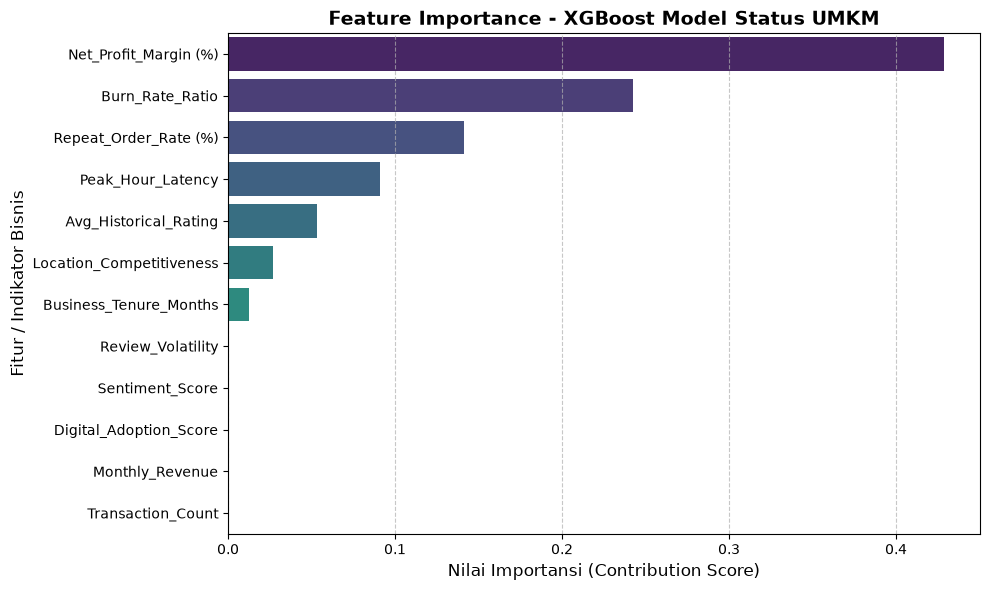

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mengambil nilai importance dari model XGBoost yang sudah dilatih
importances = model.feature_importances_
feature_names = X.columns

# 2. Menggabungkan nama fitur dan nilainya ke dalam DataFrame
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Menampilkan tabel 10 fitur teratas di terminal/output Colab
print("--- TABEL RANKING FITUR PALING BERPENGARUH ---")
print(df_importance.to_string(index=False))

# 4. Membuat Visualisasi Grafik Batang (Bar Chart)
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=df_importance,
    palette='viridis'
)

# Menambahkan judul dan label grafik
plt.title('Feature Importance - XGBoost Model Status UMKM', fontsize=14, fontweight='bold')
plt.xlabel('Nilai Importansi (Contribution Score)', fontsize=12)
plt.ylabel('Fitur / Indikator Bisnis', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Menampilkan grafik
plt.tight_layout()
plt.show()

--- SUMMARY PLOT SHAP (Dampak Seluruh Fitur) ---


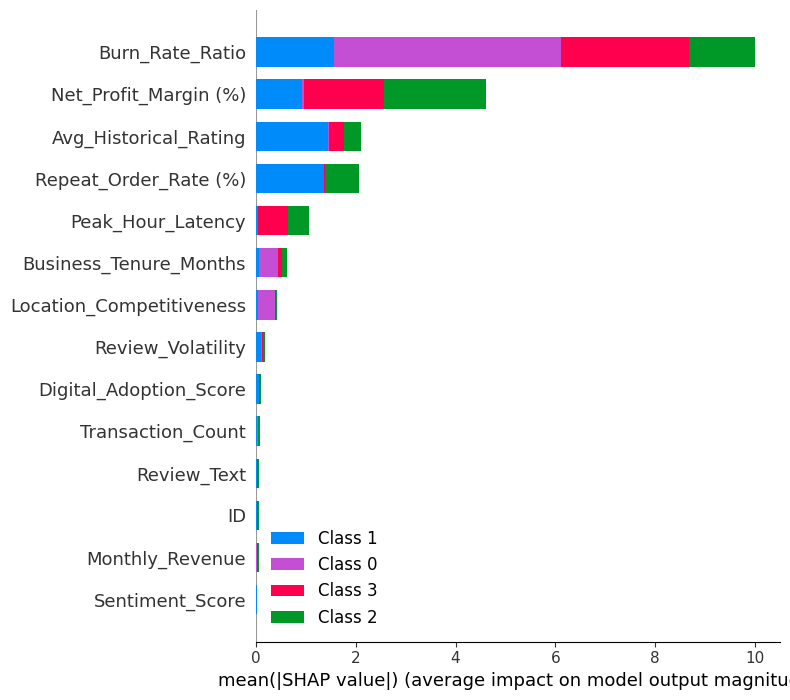


--- WATERFALL PLOT SHAP (Alasan Diagnosa untuk UMKM Ke-1) ---


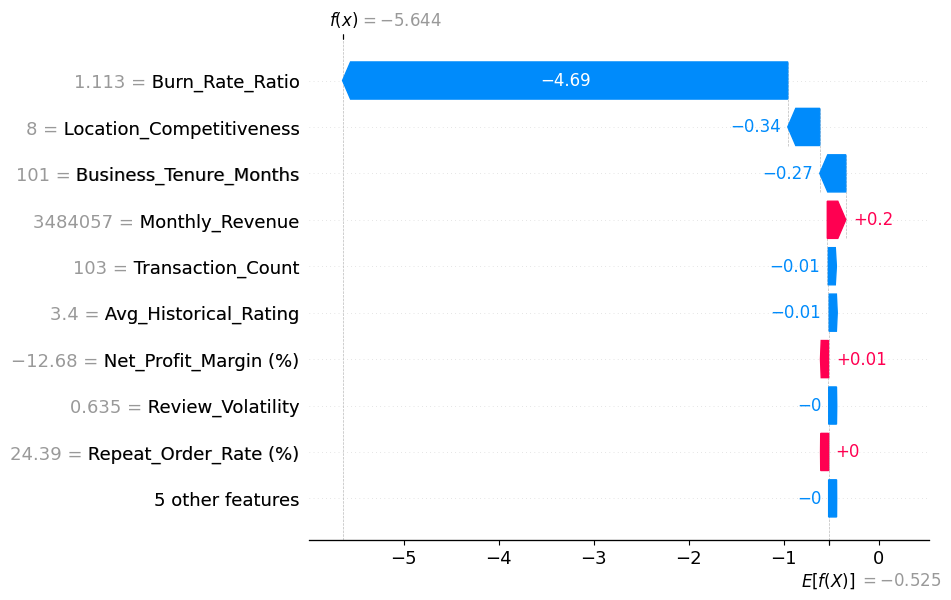

In [ ]:
# 1. Install library SHAP jika belum ada
!pip install shap -q

import shap
import matplotlib.pyplot as plt

# 2. Buat TreeExplainer khusus untuk model XGBoost
explainer = shap.TreeExplainer(model)

# 3. Hitung SHAP values pada data uji (X_test)
# Untuk menghemat waktu dan memori Colab, kita ambil 1.000 sampel dari X_test
X_sample = X_test.iloc[:1000]
shap_values = explainer(X_sample)

# 4. VISUALISASI 1: Summary Beeswarm Plot (Global Impact)
print("--- SUMMARY PLOT SHAP (Dampak Seluruh Fitur) ---")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample)

# 5. VISUALISASI 2: Waterfall Plot (Dampak Spesifik untuk 1 UMKM Pertama)
print("\n--- WATERFALL PLOT SHAP (Alasan Diagnosa untuk UMKM Ke-1) ---")
# Menampilkan penjelasan untuk UMKM pertama di X_sample untuk kelas target tertentu (misal kelas 0 / Critical)
shap.plots.waterfall(shap_values[0, :, 0])

In [5]:
import pickle

# Menyimpan model XGBoost
with open('xgboost_umkm_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# Menyimpan Label Encoder untuk target (Class) agar bisa dibaca kembali teksnya
with open('label_encoder_y.pkl', 'wb') as f:
    pickle.dump(le_y, f)

print("File model dan encoder berhasil disimpan!")

File model dan encoder berhasil disimpan!
